<a href="https://colab.research.google.com/github/chaithu-gif/AI_LAB/blob/main/DEVaat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

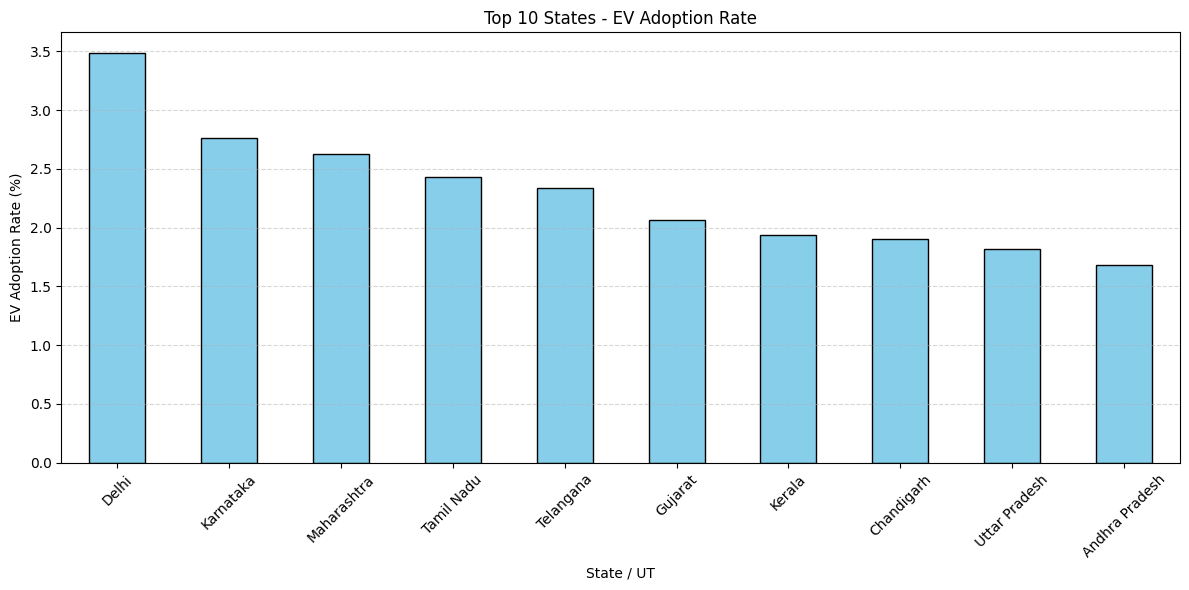

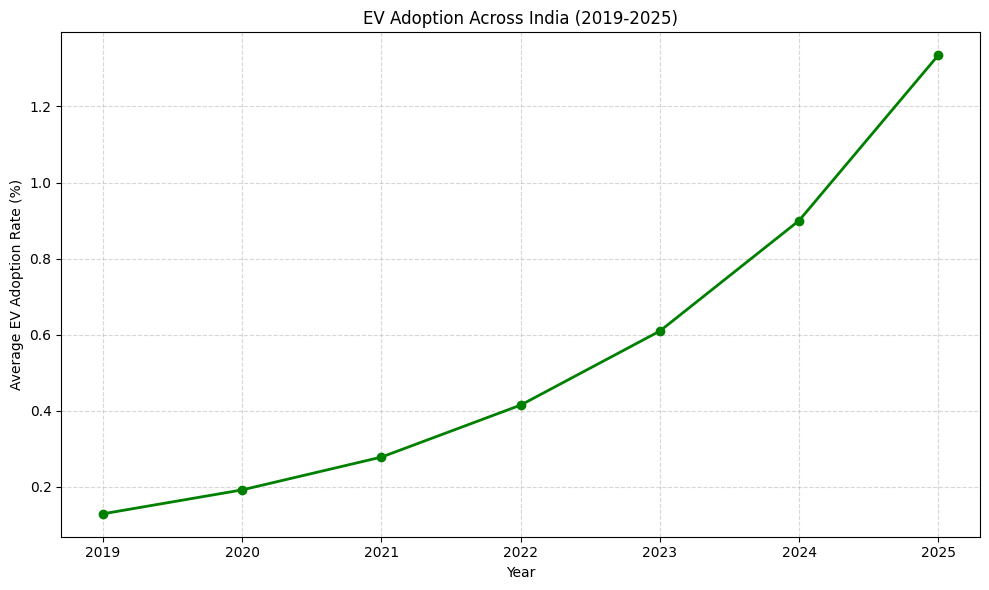

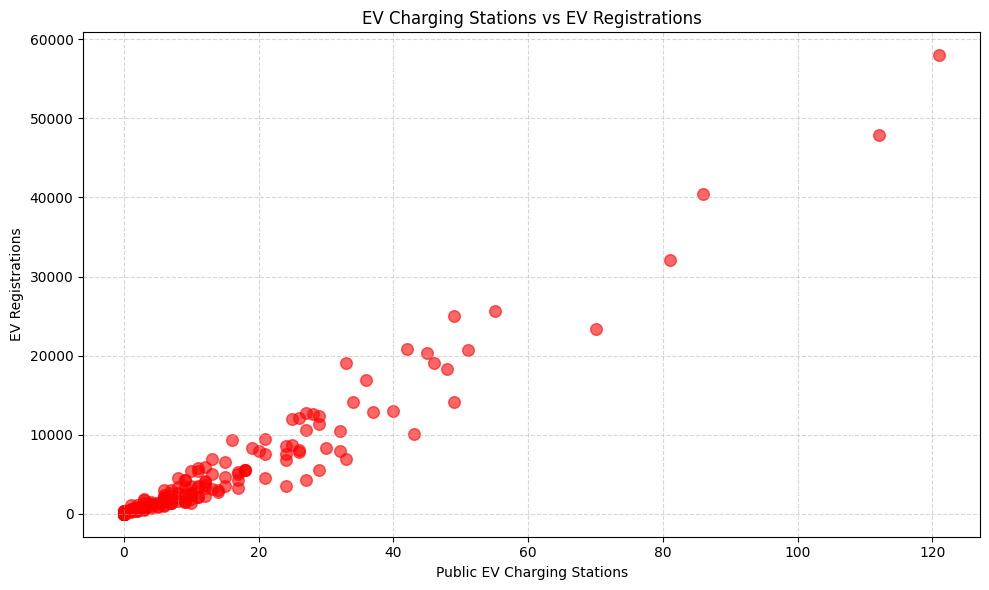

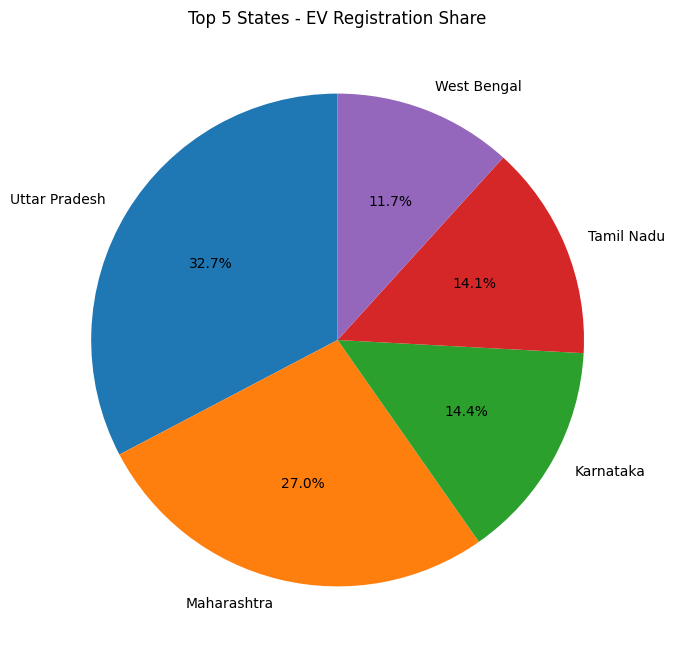

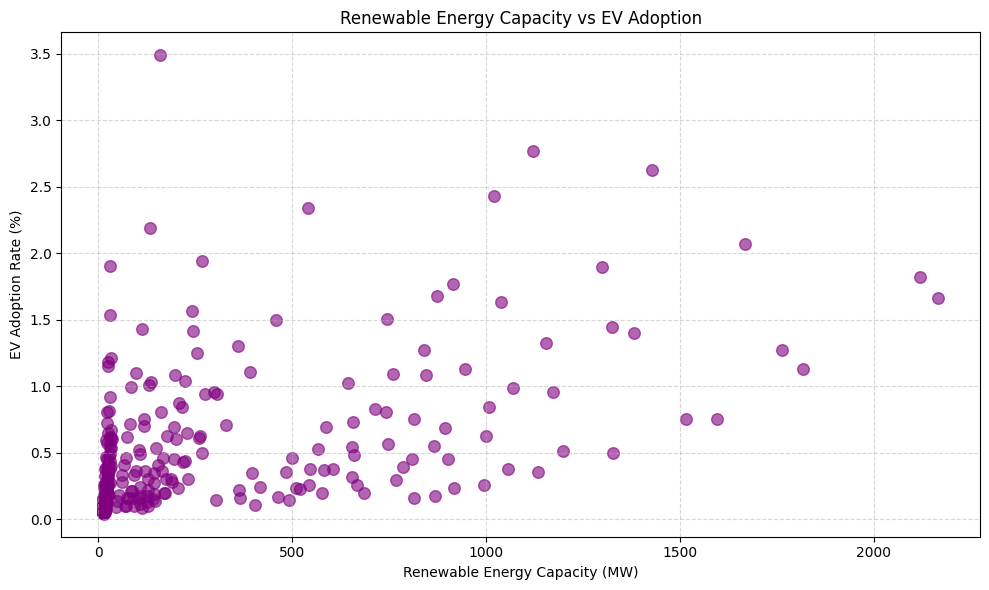

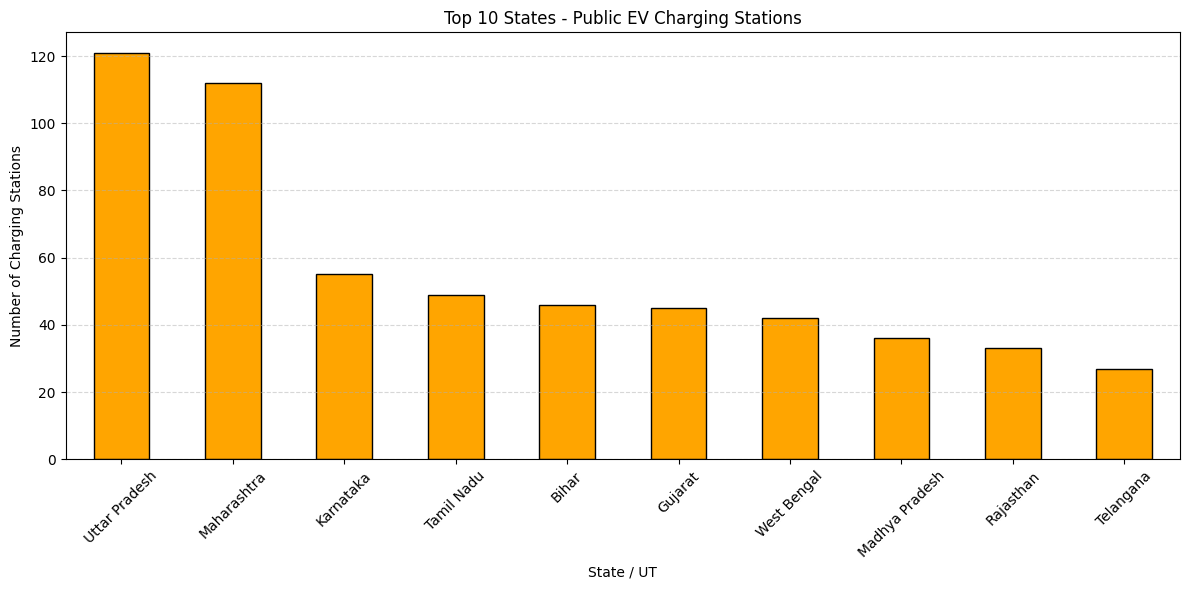

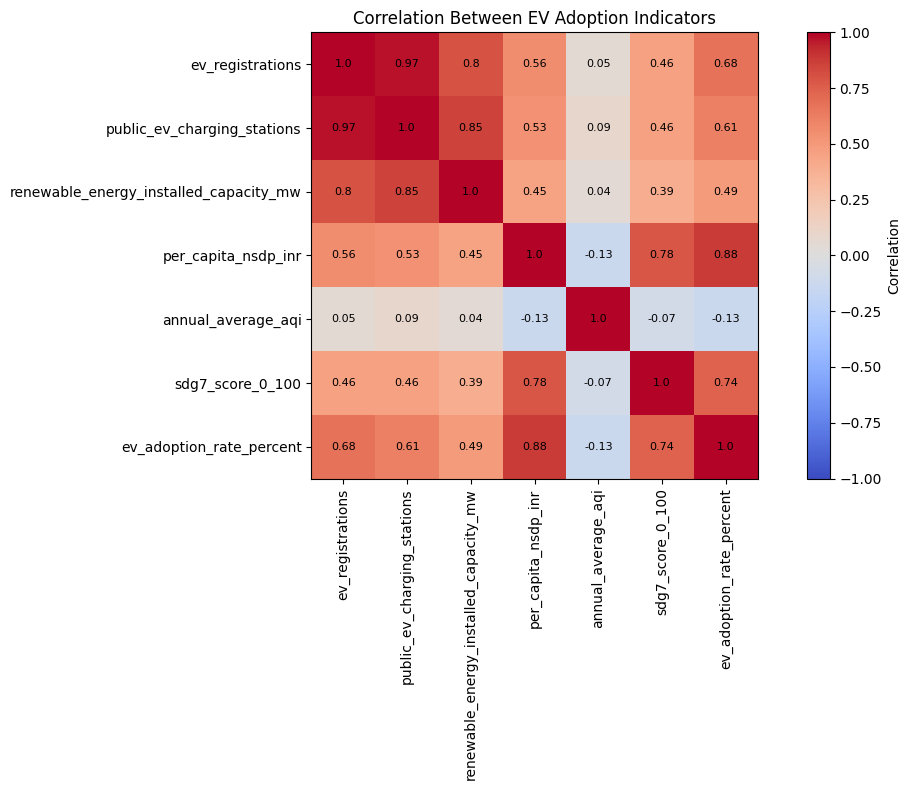

In [1]:

import pandas as pd
import matplotlib.pyplot as plt

# Import Excel dataset
df = pd.read_excel("evision_india_10_indicators_synthetic_2019_2025.xlsx")

# -----------------------------------------
# 1. BAR CHART - EV Adoption by State
# -----------------------------------------

latest_year = df["year"].max()

latest = df[df["year"] == latest_year]

state_ev = latest.groupby("state_or_ut")[
    "ev_adoption_rate_percent"
].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))

state_ev.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Top 10 States - EV Adoption Rate")
plt.xlabel("State / UT")
plt.ylabel("EV Adoption Rate (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# -----------------------------------------
# 2. LINE CHART - EV Adoption Over Years
# -----------------------------------------

year_ev = df.groupby("year")[
    "ev_adoption_rate_percent"
].mean()

plt.figure(figsize=(10, 6))

plt.plot(
    year_ev.index,
    year_ev.values,
    marker="o",
    color="green",
    linewidth=2
)

plt.title("EV Adoption Across India (2019-2025)")
plt.xlabel("Year")
plt.ylabel("Average EV Adoption Rate (%)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# -----------------------------------------
# 3. SCATTER PLOT - Charging Stations vs EVs
# -----------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    df["public_ev_charging_stations"],
    df["ev_registrations"],
    color="red",
    s=70,
    alpha=0.6
)

plt.title("EV Charging Stations vs EV Registrations")
plt.xlabel("Public EV Charging Stations")
plt.ylabel("EV Registrations")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# -----------------------------------------
# 4. PIE CHART - EV Registrations by State
# -----------------------------------------

top_states = latest.groupby("state_or_ut")[
    "ev_registrations"
].sum().sort_values(ascending=False).head(5)

plt.figure(figsize=(8, 8))

plt.pie(
    top_states,
    labels=top_states.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Top 5 States - EV Registration Share")
plt.show()

# -----------------------------------------
# 5. SCATTER PLOT - Renewable Energy vs EV
# -----------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    df["renewable_energy_installed_capacity_mw"],
    df["ev_adoption_rate_percent"],
    color="purple",
    s=70,
    alpha=0.6
)

plt.title("Renewable Energy Capacity vs EV Adoption")
plt.xlabel("Renewable Energy Capacity (MW)")
plt.ylabel("EV Adoption Rate (%)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# -----------------------------------------
# 6. BAR CHART - Charging Stations by State
# -----------------------------------------

charging = latest.groupby("state_or_ut")[
    "public_ev_charging_stations"
].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))

charging.plot(kind="bar", color="orange", edgecolor="black")

plt.title("Top 10 States - Public EV Charging Stations")
plt.xlabel("State / UT")
plt.ylabel("Number of Charging Stations")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# -----------------------------------------
# 7. CORRELATION HEATMAP
# -----------------------------------------

columns = [
    "ev_registrations",
    "public_ev_charging_stations",
    "renewable_energy_installed_capacity_mw",
    "per_capita_nsdp_inr",
    "annual_average_aqi",
    "sdg7_score_0_100",
    "ev_adoption_rate_percent"
]

corr = df[columns].corr()

plt.figure(figsize=(12, 8))

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(range(len(columns)), columns, rotation=90)
plt.yticks(range(len(columns)), columns)

plt.title("Correlation Between EV Adoption Indicators")

for i in range(len(columns)):
    for j in range(len(columns)):
        plt.text(j, i, round(corr.iloc[i, j], 2),
                 ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.show()
